In [4]:
import pandas as pd 
df = pd.read_csv("datos_region_andina.xls")

In [1]:
"""
Preparacion minima de datos SECOP: tipos, nombres normalizados y duplicados.

Principio: MARCAR, no borrar. Lo unico que se elimina por defecto son las filas
100% identicas (repetidas exactas). Todo lo demas queda en columnas flag_* para
que decidas tu.
"""
import os
import re
import sys
import unicodedata

import numpy as np
import pandas as pd

# ===========================================================================
# RUTAS DE ENTRADA Y SALIDA (Deja descomentada la que quieras preparar)
# ===========================================================================
ARCHIVO = r"D:\Proyecto final\PArte 1\datos_region_andina.xls"
# ARCHIVO = r"D:\Proyecto final\PArte 1\SECOP_15-26.csv"
# ARCHIVO = r"D:\Proyecto final\PArte 1\SECOP_23-26.csv"
# ARCHIVO = r"D:\Proyecto final\PArte 1\SECOP_200K_CON_TODOS_LOS_MEDICAMENTOS.csv"

SALIDA = r"D:\Proyecto final\PArte 1\salida_preparacion"
ARCHIVO_PREPARADO_PARQUET = r"D:\Proyecto final\PArte 1\contratos_preparados.parquet"
ARCHIVO_PREPARADO_CSV = r"D:\Proyecto final\PArte 1\contratos_preparados.csv"

DAYFIRST = False        # True si tus fechas vienen como dd/mm/aaaa
ANIO_MIN, ANIO_MAX = 2000, 2026

COLS_FECHA = ["fecha_de_firma", "fecha_de_inicio_del_contrato", "fecha_de_fin_del_contrato"]
COLS_TEXTO = ["nombre_entidad", "proveedor_adjudicado", "departamento", "ciudad", "sector",
              "rama", "orden", "estado_contrato", "tipo_de_contrato",
              "modalidad_de_contratacion", "es_pyme", "origen_de_los_recursos", "destino_gasto"]
PLACEHOLDERS = {"NO DEFINIDO", "NO DEFINIDA", "NO APLICA", "N A", "NA", "NULL", "NONE",
                "SIN DATO", "SIN INFORMACION", "NO REGISTRA", "NO ASIGNADO"}


# ---------------------------------------------------------------------------
# Normalizacion de texto
# ---------------------------------------------------------------------------
def normalizar(texto):
    """MAYUSCULAS, sin tildes, sin puntuacion, espacios colapsados. Vacio -> NaN."""
    if pd.isna(texto):
        return np.nan
    t = unicodedata.normalize("NFKD", str(texto))
    t = "".join(c for c in t if not unicodedata.combining(c))
    t = t.upper().replace(".", "")            # E.S.E. -> ESE, S.A.S. -> SAS
    t = re.sub(r"[^\w\s]", " ", t)            # el resto de signos -> espacio
    t = re.sub(r"\s+", " ", t).strip()
    return t if t else np.nan


def normalizar_serie(s):
    """Normaliza solo los valores unicos y los mapea (mucho mas rapido que fila a fila)."""
    mapa = {v: normalizar(v) for v in s.dropna().unique()}
    return s.map(mapa)


# ---------------------------------------------------------------------------
# 1. Conversion de tipos
# ---------------------------------------------------------------------------
def _a_fecha(s):
    try:
        return pd.to_datetime(s, errors="coerce", dayfirst=DAYFIRST, format="mixed")
    except (ValueError, TypeError):           # pandas < 2.0 no acepta format="mixed"
        return pd.to_datetime(s, errors="coerce", dayfirst=DAYFIRST)


def convertir_tipos(df):
    df = df.copy()
    print("=== 1. Conversion de tipos ===")

    # Identificadores como texto limpio
    df["id_contrato"] = df["id_contrato"].astype("string").str.strip()
    c = "n_mero_de_documento_ordenador_del_gasto"
    if c in df.columns:
        df[c] = df[c].astype("string").str.strip().str.replace(r"\.0$", "", regex=True)

    # Valor del contrato -> numerico
    original = df["valor_del_contrato"]
    num = pd.to_numeric(original, errors="coerce")
    fallidos = original.notna() & num.isna()
    print(f"valor_del_contrato: {int(fallidos.sum()):,} valores no convertibles"
          + (f" (ej: {list(original[fallidos].unique()[:5])})" if fallidos.any() else ""))
    df["valor_del_contrato"] = num

    # Fechas -> datetime
    for col in COLS_FECHA:
        if col not in df.columns:
            continue
        original = df[col]
        f = _a_fecha(original)
        fallidos = original.notna() & f.isna()
        print(f"{col}: {int(fallidos.sum()):,} no convertibles, {int(f.isna().sum()):,} nulos en total"
              + (f" (ej: {list(original[fallidos].unique()[:5])})" if fallidos.any() else ""))
        df[col] = f

    # Derivadas y banderas (se marcan, no se borran)
    df["dur_dias"] = (df["fecha_de_fin_del_contrato"] - df["fecha_de_inicio_del_contrato"]).dt.days
    df["plazo_firma_inicio"] = (df["fecha_de_inicio_del_contrato"] - df["fecha_de_firma"]).dt.days
    anio = df["fecha_de_firma"].dt.year
    df["flag_valor_invalido"] = ~(df["valor_del_contrato"] > 0)          # nulo, cero o negativo
    df["flag_fin_antes_inicio"] = df["dur_dias"] < 0
    df["flag_anio_firma_raro"] = (anio < ANIO_MIN) | (anio > ANIO_MAX)
    for fl in ["flag_valor_invalido", "flag_fin_antes_inicio", "flag_anio_firma_raro"]:
        print(f"{fl}: {int(df[fl].sum()):,} filas")
    return df


# ---------------------------------------------------------------------------
# 2. Normalizacion de nombres y categorias
# ---------------------------------------------------------------------------
def normalizar_columnas(df, columnas=COLS_TEXTO):
    df = df.copy()
    print("\n=== 2. Normalizacion de nombres y categorias ===")
    filas = []
    for c in columnas:
        if c not in df.columns:
            continue
        df[c + "_norm"] = normalizar_serie(df[c])
        crudos, norm = df[c].nunique(), df[c + "_norm"].nunique()
        filas.append({
            "columna": c,
            "nulos": int(df[c].isna().sum()),
            "unicos_crudos": crudos,
            "unicos_normalizados": norm,
            "variantes_que_sobran": crudos - norm,
            "valores_placeholder": int(df[c + "_norm"].isin(PLACEHOLDERS).sum()),
        })
        if crudos > norm:       # guarda los grupos de variantes para revisarlos
            u = pd.DataFrame({"orig": df[c], "norm": df[c + "_norm"]}).dropna().drop_duplicates()
            n_var = u.groupby("norm")["orig"].transform("nunique")
            g = u[n_var > 1].groupby("norm")["orig"].agg(lambda x: " | ".join(sorted(x)))
            g.rename("variantes").to_csv(f"{SALIDA}/variantes_{c}.csv")

    # Alias directo 'entidad_norm' para compatibilidad con scripts de KPIs y PCA
    if "nombre_entidad_norm" in df.columns:
        df["entidad_norm"] = df["nombre_entidad_norm"]

    resumen = pd.DataFrame(filas)
    resumen.to_csv(f"{SALIDA}/resumen_normalizacion.csv", index=False)
    print(resumen.to_string(index=False))
    print(f"-> variantes por columna en {SALIDA}/variantes_<columna>.csv")
    return df


# ---------------------------------------------------------------------------
# 3. Duplicados
# ---------------------------------------------------------------------------
def revisar_duplicados(df):
    """Devuelve (reporte, ids_con_versiones_distintas, mascara_filas_exactas_repetidas)."""
    print("\n=== 3. Duplicados ===")
    cols_orig = [c for c in df.columns
                 if not c.endswith("_norm") and not c.startswith("flag_")
                 and c not in ("dur_dias", "plazo_firma_inicio")]
    rep = {"id_nulo": int(df["id_contrato"].isna().sum())}

    # a) filas 100% identicas: se pueden eliminar sin riesgo
    exactos = df.duplicated(subset=cols_orig, keep="first")
    rep["filas_exactamente_repetidas"] = int(exactos.sum())
    print(f"Filas 100% identicas (sobran): {rep['filas_exactamente_repetidas']:,}")
    print(f"id_contrato nulo: {rep['id_nulo']:,}")

    # b) mismo id_contrato pero contenido distinto: modificaciones/adiciones o errores
    u = df.loc[~exactos.to_numpy()]
    en_conflicto = u["id_contrato"].notna() & u.duplicated("id_contrato", keep=False)
    conflicto = u[en_conflicto]
    ids_conf = set(conflicto["id_contrato"].unique())
    rep["ids_con_versiones_distintas"] = len(ids_conf)
    print(f"id_contrato repetido con contenido distinto: {len(ids_conf):,} ids "
          f"({len(conflicto):,} filas)")
    if len(conflicto):
        var = conflicto[cols_orig].groupby("id_contrato").nunique(dropna=False)
        cambian = (var > 1).sum().sort_values(ascending=False)
        cambian = cambian[cambian > 0]
        print("Columnas que mas cambian entre las versiones de un mismo id:")
        print(cambian.head(8).to_string())
        conflicto.sort_values("id_contrato").to_csv(
            f"{SALIDA}/ids_con_versiones_distintas.csv", index=False)
        print(f"-> {SALIDA}/ids_con_versiones_distintas.csv")

    # c) duplicados "logicos": ids distintos pero mismo contrato en lo esencial
    clave = [c for c in ["nombre_entidad_norm", "proveedor_adjudicado_norm", "valor_del_contrato",
                         "fecha_de_firma", "objeto_del_contrato"] if c in df.columns]
    if len(clave) == 5:
        base = u.drop_duplicates("id_contrato").dropna(subset=clave)
        logico = base[base.duplicated(clave, keep=False)]
        rep["filas_posibles_duplicados_logicos"] = len(logico)
        print(f"Posibles duplicados logicos (distinto id, misma entidad/proveedor/valor/"
              f"fecha/objeto): {len(logico):,} filas")
        if len(logico):
            logico.sort_values(clave).to_csv(f"{SALIDA}/duplicados_logicos.csv", index=False)
            print(f"-> {SALIDA}/duplicados_logicos.csv (pueden ser legitimos: revisar a mano)")
    return rep, ids_conf, exactos


# ---------------------------------------------------------------------------
def preparar(df, eliminar_exactos=True):
    os.makedirs(SALIDA, exist_ok=True)
    df = df.reset_index(drop=True)
    n0 = len(df)
    df = convertir_tipos(df)
    df = normalizar_columnas(df)
    rep, ids_conf, exactos = revisar_duplicados(df)
    if eliminar_exactos:
        df = df.loc[~exactos.to_numpy()].copy()
    df["id_repetido"] = df["id_contrato"].isin(ids_conf)   # version distinta con mismo id
    print(f"\n=== Resumen ===\nFilas de entrada: {n0:,} | eliminadas (identicas): "
          f"{n0 - len(df):,} | filas finales: {len(df):,}")
    print("Columnas nuevas: entidad_norm, *_norm, dur_dias, plazo_firma_inicio, flag_*, id_repetido")
    return df, rep


if __name__ == "__main__":
    ruta = ARCHIVO
    # dtype=str: sin inferencia automatica, los ids y documentos no pierden ceros ni ganan ".0"
    try:
        datos = pd.read_csv(ruta, dtype=str, low_memory=False)
    except Exception:
        datos = pd.read_excel(ruta, dtype=str)

    print(f"{len(datos):,} filas, {datos.shape[1]} columnas\n")
    df_prep, reporte = preparar(datos)

    # Verificacion rapida de preparacion minima para KPIs
    print("\n=== Verificacion de Preparacion Minima para KPIs ===")
    print(f"- valor_del_contrato dtype:            {df_prep['valor_del_contrato'].dtype}")
    print(f"- fecha_de_firma dtype:                {df_prep['fecha_de_firma'].dtype}")
    print(f"- fecha_de_inicio_del_contrato dtype:  {df_prep['fecha_de_inicio_del_contrato'].dtype}")
    print(f"- fecha_de_fin_del_contrato dtype:     {df_prep['fecha_de_fin_del_contrato'].dtype}")
    print(f"- entidad_norm creada (unicos):        {df_prep['entidad_norm'].nunique():,}")

    try:
        df_prep.to_parquet(ARCHIVO_PREPARADO_PARQUET, index=False)
        print(f"\nGuardado: {ARCHIVO_PREPARADO_PARQUET}")
    except Exception:
        df_prep.to_csv(ARCHIVO_PREPARADO_CSV, index=False)
        print(f"\nGuardado: {ARCHIVO_PREPARADO_CSV}")

329,241 filas, 23 columnas

=== 1. Conversion de tipos ===
valor_del_contrato: 0 valores no convertibles
fecha_de_firma: 0 no convertibles, 0 nulos en total
fecha_de_inicio_del_contrato: 0 no convertibles, 1,912 nulos en total
fecha_de_fin_del_contrato: 0 no convertibles, 2 nulos en total
flag_valor_invalido: 3,125 filas
flag_fin_antes_inicio: 35 filas
flag_anio_firma_raro: 0 filas

=== 2. Normalizacion de nombres y categorias ===
                  columna  nulos  unicos_crudos  unicos_normalizados  variantes_que_sobran  valores_placeholder
           nombre_entidad      0           2062                 2061                     1                    0
     proveedor_adjudicado      4         234621               233423                  1198                   68
             departamento      0             11                   11                     0                    0
                   ciudad      0            492                  492                     0                80723
     

In [7]:
"""¿Qué nos dice?
Mide si el presupuesto de la entidad está repartido entre muchos contratistas o concentrado en unos pocos. Va de 0 a 1:

Cercano a 0 (ej. 0.02): Competencia sana; el dinero se reparte entre decenas o cientos de proveedores.

Cercano a 1 (ej. 0.80): Monopolio o alta concentración; uno o dos proveedores se llevan casi todo el presupuesto de la entidad."""

# 0. Nos aseguramos de usar el DataFrame preparado (df_prep) y solo contratos con valor > 0
df_clean = df_prep[df_prep["valor_del_contrato"] > 0].copy()

# 1. Creamos la tabla base por entidad (df_entidades) con total_contratos y total_valor
df_entidades = df_clean.groupby("entidad_norm").agg(
    total_contratos=("id_contrato", "nunique"),
    total_valor=("valor_del_contrato", "sum")
)

# 2. Sumamos cuánto dinero ganó cada proveedor dentro de cada entidad (usando nombres normalizados)
prov_valor = df_clean.groupby(["entidad_norm", "proveedor_adjudicado_norm"])[
    "valor_del_contrato"
].sum()

# 3. Calculamos la participación de cada proveedor sobre el total de su entidad
participacion_valor = prov_valor / df_entidades["total_valor"]

# 4. Elevamos al cuadrado y sumamos por entidad (HHI en escala 0 a 1)
df_entidades["hhi_valor"] = (
    (participacion_valor ** 2).groupby("entidad_norm").sum()
)

# 5. Revisamos los primeros resultados
print(df_entidades[["total_contratos", "total_valor", "hhi_valor"]].head(10))

                                                    total_contratos  \
entidad_norm                                                          
ACI MEDELLIN                                                     15   
ACOPI ANTIOQUIA                                                  19   
ADMINISTRADORA COLOMBIANA DE PENSIONES COLPENSI...               13   
ADRES                                                           465   
AEROCIVIL                                                       852   
AEROPUERTO INTERNACIONAL MATECANA                                44   
AEROPUERTO OLAYA HERRERA                                         36   
AGENCIA CATASTRAL DE CUNDINAMARCA                               141   
AGENCIA DE COMERCIALIZACION Y DE COMPETITIVIDAD...              179   
AGENCIA DE CUNDINAMARCA PARA LA PAZ Y LA CONVIV...                7   

                                                     total_valor  hhi_valor  
entidad_norm                                                         

In [10]:
#KPI 2
# Contamos cuántos contratos únicos ganó cada proveedor normalizado dentro de cada entidad
prov_n = df_clean.groupby(["entidad_norm", "proveedor_adjudicado_norm"])[
    "id_contrato"
].nunique()

# Calculamos el porcentaje de contratos de cada proveedor sobre el total de su entidad
participacion_n = prov_n / df_entidades["total_contratos"]

# Elevamos al cuadrado y sumamos por entidad
df_entidades["hhi_n"] = (participacion_n ** 2).groupby("entidad_norm").sum()

# Comparamos ambos HHI
print(df_entidades[["total_contratos", "hhi_valor", "hhi_n"]].head(10))

                                                    total_contratos  \
entidad_norm                                                          
ACI MEDELLIN                                                     15   
ACOPI ANTIOQUIA                                                  19   
ADMINISTRADORA COLOMBIANA DE PENSIONES COLPENSI...               13   
ADRES                                                           465   
AEROCIVIL                                                       852   
AEROPUERTO INTERNACIONAL MATECANA                                44   
AEROPUERTO OLAYA HERRERA                                         36   
AGENCIA CATASTRAL DE CUNDINAMARCA                               141   
AGENCIA DE COMERCIALIZACION Y DE COMPETITIVIDAD...              179   
AGENCIA DE CUNDINAMARCA PARA LA PAZ Y LA CONVIV...                7   

                                                    hhi_valor     hhi_n  
entidad_norm                                                             

In [11]:
#KPI 3
# Filtramos los contratos cuya modalidad sea Contratación Directa
es_directa = df_clean['modalidad_de_contratacion'].str.contains(
    'directa', case=False, na=False
)

# Sumamos el valor de esos contratos por entidad (si una entidad no tiene, ponemos 0)
valor_directa = (
    df_clean[es_directa]
    .groupby('entidad_norm')['valor_del_contrato']
    .sum()
    .reindex(df_entidades.index, fill_value=0)
)

# Dividimos sobre el presupuesto total de la entidad
df_entidades['pct_valor_directa'] = valor_directa / df_entidades['total_valor']

print(df_entidades[['hhi_valor', 'hhi_n', 'pct_valor_directa']].head(10))

                                                    hhi_valor     hhi_n  \
entidad_norm                                                              
ACI MEDELLIN                                         0.139619  0.075556   
ACOPI ANTIOQUIA                                      0.119750  0.052632   
ADMINISTRADORA COLOMBIANA DE PENSIONES COLPENSI...   0.205444  0.076923   
ADRES                                                0.426580  0.003251   
AEROCIVIL                                            0.040157  0.001942   
AEROPUERTO INTERNACIONAL MATECANA                    0.430280  0.025826   
AEROPUERTO OLAYA HERRERA                             0.530803  0.041667   
AGENCIA CATASTRAL DE CUNDINAMARCA                    0.411610  0.009104   
AGENCIA DE COMERCIALIZACION Y DE COMPETITIVIDAD...   0.287486  0.008146   
AGENCIA DE CUNDINAMARCA PARA LA PAZ Y LA CONVIV...   0.189898  0.142857   

                                                    pct_valor_directa  
entidad_norm               

In [12]:
#KPI 4
# Filtramos los contratos cuya modalidad sea Régimen Especial
es_reg_esp = df_clean['modalidad_de_contratacion'].str.contains(
    'régimen especial|regimen especial', case=False, na=False
)

# Sumamos el valor por entidad
valor_reg_esp = (
    df_clean[es_reg_esp]
    .groupby('entidad_norm')['valor_del_contrato']
    .sum()
    .reindex(df_entidades.index, fill_value=0)
)

# Dividimos sobre el presupuesto total
df_entidades['pct_valor_regimen_esp'] = (
    valor_reg_esp / df_entidades['total_valor']
)

print(df_entidades[['pct_valor_directa', 'pct_valor_regimen_esp']].head(10))

                                                    pct_valor_directa  \
entidad_norm                                                            
ACI MEDELLIN                                                 0.633595   
ACOPI ANTIOQUIA                                              0.000000   
ADMINISTRADORA COLOMBIANA DE PENSIONES COLPENSI...           0.000000   
ADRES                                                        0.900162   
AEROCIVIL                                                    0.272193   
AEROPUERTO INTERNACIONAL MATECANA                            0.035207   
AEROPUERTO OLAYA HERRERA                                     0.973291   
AGENCIA CATASTRAL DE CUNDINAMARCA                            0.958160   
AGENCIA DE COMERCIALIZACION Y DE COMPETITIVIDAD...           0.998578   
AGENCIA DE CUNDINAMARCA PARA LA PAZ Y LA CONVIV...           0.770914   

                                                    pct_valor_regimen_esp  
entidad_norm                                   

In [13]:
#KPI 5
# Filtramos los contratos de Prestación de Servicios
es_ops = df_clean['tipo_de_contrato'].str.contains(
    'Prestación de servicios|Prestacion de servicios', case=False, na=False
)

# Contamos cuántos contratos OPS tiene cada entidad
conteo_ops = (
    df_clean[es_ops]
    .groupby('entidad_norm')['id_contrato']
    .count()
    .reindex(df_entidades.index, fill_value=0)
)

# Dividimos sobre el total de contratos de la entidad
df_entidades['pct_contratos_ops'] = conteo_ops / df_entidades['total_contratos']

print(
    df_entidades[[
        'pct_valor_directa',
        'pct_valor_regimen_esp',
        'pct_contratos_ops',
    ]].head(10)
)

                                                    pct_valor_directa  \
entidad_norm                                                            
ACI MEDELLIN                                                 0.633595   
ACOPI ANTIOQUIA                                              0.000000   
ADMINISTRADORA COLOMBIANA DE PENSIONES COLPENSI...           0.000000   
ADRES                                                        0.900162   
AEROCIVIL                                                    0.272193   
AEROPUERTO INTERNACIONAL MATECANA                            0.035207   
AEROPUERTO OLAYA HERRERA                                     0.973291   
AGENCIA CATASTRAL DE CUNDINAMARCA                            0.958160   
AGENCIA DE COMERCIALIZACION Y DE COMPETITIVIDAD...           0.998578   
AGENCIA DE CUNDINAMARCA PARA LA PAZ Y LA CONVIV...           0.770914   

                                                    pct_valor_regimen_esp  \
entidad_norm                                  

In [14]:
#KPI 6
# Verificamos los valores de 'es_pyme' (en SECOP II suele venir como 'Si' / 'No')
es_pyme_flag = (
    df_clean['es_pyme']
    .astype(str)
    .str.strip()
    .str.upper()
    .isin(['SI', 'SÍ', 'TRUE', '1'])
)

# Sumamos el dinero adjudicado a Pymes por entidad
valor_pyme = (
    df_clean[es_pyme_flag]
    .groupby('entidad_norm')['valor_del_contrato']
    .sum()
    .reindex(df_entidades.index, fill_value=0)
)

# Dividimos sobre el presupuesto total de la entidad
df_entidades['pct_valor_pyme'] = valor_pyme / df_entidades['total_valor']

print(df_entidades[['pct_contratos_ops', 'pct_valor_pyme']].head(10))

                                                    pct_contratos_ops  \
entidad_norm                                                            
ACI MEDELLIN                                                 1.000000   
ACOPI ANTIOQUIA                                              1.000000   
ADMINISTRADORA COLOMBIANA DE PENSIONES COLPENSI...           0.923077   
ADRES                                                        0.972043   
AEROCIVIL                                                    0.687793   
AEROPUERTO INTERNACIONAL MATECANA                            0.704545   
AEROPUERTO OLAYA HERRERA                                     0.805556   
AGENCIA CATASTRAL DE CUNDINAMARCA                            0.936170   
AGENCIA DE COMERCIALIZACION Y DE COMPETITIVIDAD...           0.932961   
AGENCIA DE CUNDINAMARCA PARA LA PAZ Y LA CONVIV...           0.428571   

                                                    pct_valor_pyme  
entidad_norm                                          

In [15]:
# KPI 7 
#Aseguramos tener el mes de firma extraído
mes_firma = pd.to_datetime(
    df_clean['fecha_de_firma'], errors='coerce'
).dt.month

# Filtramos contratos firmados en Enero (1) o Febrero (2)
es_ene_feb = mes_firma.isin([1, 2])

# Sumamos el dinero firmado en esos dos meses por entidad
valor_ene_feb = (
    df_clean[es_ene_feb]
    .groupby('entidad_norm')['valor_del_contrato']
    .sum()
    .reindex(df_entidades.index, fill_value=0)
)

# Dividimos sobre el presupuesto total de la entidad
df_entidades['pct_valor_ene_feb'] = valor_ene_feb / df_entidades['total_valor']

print(df_entidades[['pct_valor_pyme', 'pct_valor_ene_feb']].head(10))

                                                    pct_valor_pyme  \
entidad_norm                                                         
ACI MEDELLIN                                              0.384034   
ACOPI ANTIOQUIA                                           0.461144   
ADMINISTRADORA COLOMBIANA DE PENSIONES COLPENSI...        0.251918   
ADRES                                                     0.086004   
AEROCIVIL                                                 0.464555   
AEROPUERTO INTERNACIONAL MATECANA                         0.961724   
AEROPUERTO OLAYA HERRERA                                  0.036083   
AGENCIA CATASTRAL DE CUNDINAMARCA                         0.685294   
AGENCIA DE COMERCIALIZACION Y DE COMPETITIVIDAD...        0.011805   
AGENCIA DE CUNDINAMARCA PARA LA PAZ Y LA CONVIV...        0.000000   

                                                    pct_valor_ene_feb  
entidad_norm                                                           
ACI MEDELLIN   

In [16]:
# ==============================================================================
# KPI #7 (Versión B - Anual): Planeación Temprana Promedio por Año (Enero-Febrero)
# Nota: A diferencia de la Versión A ('pct_valor_ene_feb', que acumula todo el
# periodo 2020-2025 en una sola bolsa), aquí calculamos primero el porcentaje de
# cada año por separado y luego sacamos el promedio anual para dar el mismo peso
# a todos los años y evitar que un año con un megacontrato distorsione el resultado.
# ==============================================================================

# 1. Extraemos el año y el mes de firma de cada contrato
df_clean['anio_firma'] = pd.to_datetime(
    df_clean['fecha_de_firma'], errors='coerce'
).dt.year
df_clean['mes_firma'] = pd.to_datetime(
    df_clean['fecha_de_firma'], errors='coerce'
).dt.month

# 2. Marcamos el valor de los contratos firmados en Enero (1) o Febrero (2)
df_clean['val_ene_feb_temp'] = np.where(
    df_clean['mes_firma'].isin([1, 2]), df_clean['valor_del_contrato'], 0
)

# 3. Agrupamos primero por (Entidad + Año) para sacar el total y lo firmado en ene-feb cada año
ene_feb_anual = df_clean.groupby(['entidad_norm', 'anio_firma']).agg(
    valor_total_anio=('valor_del_contrato', 'sum'),
    valor_ene_feb_anio=('val_ene_feb_temp', 'sum'),
)

# 4. Calculamos el porcentaje de enero-febrero dentro de cada año individual
ene_feb_anual['pct_ene_feb_cada_anio'] = (
    ene_feb_anual['valor_ene_feb_anio'] / ene_feb_anual['valor_total_anio']
)

# 5. Promediamos esos porcentajes anuales para obtener el indicador final por entidad
df_entidades['pct_valor_ene_feb_anual'] = (
    ene_feb_anual.groupby('entidad_norm')['pct_ene_feb_cada_anio']
    .mean()
    .reindex(df_entidades.index, fill_value=0)
)

# Limpiamos la columna temporal
df_clean.drop(columns=['val_ene_feb_temp'], inplace=True)

# Comparamos Versión A (acumulada) vs Versión B (promedio anual)
print(df_entidades[['pct_valor_ene_feb', 'pct_valor_ene_feb_anual']].head(10))

                                                    pct_valor_ene_feb  \
entidad_norm                                                            
ACI MEDELLIN                                                 0.401663   
ACOPI ANTIOQUIA                                              0.095032   
ADMINISTRADORA COLOMBIANA DE PENSIONES COLPENSI...           0.309766   
ADRES                                                        0.084566   
AEROCIVIL                                                    0.076422   
AEROPUERTO INTERNACIONAL MATECANA                            0.013475   
AEROPUERTO OLAYA HERRERA                                     0.168875   
AGENCIA CATASTRAL DE CUNDINAMARCA                            0.195174   
AGENCIA DE COMERCIALIZACION Y DE COMPETITIVIDAD...           0.116536   
AGENCIA DE CUNDINAMARCA PARA LA PAZ Y LA CONVIV...           0.240533   

                                                    pct_valor_ene_feb_anual  
entidad_norm                                 

In [17]:
# ==============================================================================
# KPI #8: Afán Presupuestal de Cierre (Noviembre - Diciembre)
# Mide qué porcentaje del dinero se firma en los dos últimos meses del año
# (síndrome de fin de año para comprometer saldos antes del cierre de vigencia).
# ==============================================================================

# 1. Aseguramos año y mes de firma
df_clean['anio_firma'] = pd.to_datetime(
    df_clean['fecha_de_firma'], errors='coerce'
).dt.year
df_clean['mes_firma'] = pd.to_datetime(
    df_clean['fecha_de_firma'], errors='coerce'
).dt.month

# 2. Marcamos el valor de los contratos firmados en Noviembre (11) o Diciembre (12)
df_clean['val_nov_dic_temp'] = np.where(
    df_clean['mes_firma'].isin([11, 12]), df_clean['valor_del_contrato'], 0
)

# --- VERSIÓN A (Acumulado 2020-2025) ---
valor_nov_dic_acum = (
    df_clean.groupby('entidad_norm')['val_nov_dic_temp']
    .sum()
    .reindex(df_entidades.index, fill_value=0)
)
df_entidades['pct_valor_nov_dic'] = (
    valor_nov_dic_acum / df_entidades['total_valor']
)

# --- VERSIÓN B (Promedio anual real: calcula cada año por separado y promedia) ---
nov_dic_anual = df_clean.groupby(['entidad_norm', 'anio_firma']).agg(
    valor_total_anio=('valor_del_contrato', 'sum'),
    valor_nov_dic_anio=('val_nov_dic_temp', 'sum'),
)
nov_dic_anual['pct_nov_dic_cada_anio'] = (
    nov_dic_anual['valor_nov_dic_anio'] / nov_dic_anual['valor_total_anio']
)

df_entidades['pct_valor_nov_dic_anual'] = (
    nov_dic_anual.groupby('entidad_norm')['pct_nov_dic_cada_anio']
    .mean()
    .reindex(df_entidades.index, fill_value=0)
)

# Limpiamos columna temporal
df_clean.drop(columns=['val_nov_dic_temp'], inplace=True)

# Comparamos Versión A vs Versión B
print(df_entidades[['pct_valor_nov_dic', 'pct_valor_nov_dic_anual']].head(10))

                                                    pct_valor_nov_dic  \
entidad_norm                                                            
ACI MEDELLIN                                                 0.203277   
ACOPI ANTIOQUIA                                              0.061011   
ADMINISTRADORA COLOMBIANA DE PENSIONES COLPENSI...           0.198226   
ADRES                                                        0.024244   
AEROCIVIL                                                    0.172013   
AEROPUERTO INTERNACIONAL MATECANA                            0.438641   
AEROPUERTO OLAYA HERRERA                                     0.041787   
AGENCIA CATASTRAL DE CUNDINAMARCA                            0.654357   
AGENCIA DE COMERCIALIZACION Y DE COMPETITIVIDAD...           0.160770   
AGENCIA DE CUNDINAMARCA PARA LA PAZ Y LA CONVIV...           0.000000   

                                                    pct_valor_nov_dic_anual  
entidad_norm                                 

In [18]:
# ==============================================================================
# KPI #9: Concentración de Ordenadores del Gasto (HHI Ordenador - Promedio Anual)
# Mide si una sola cédula firma todo el presupuesto anual o si está delegado
# entre varios directivos.
# ==============================================================================

# 1. Limpiamos la columna de documento (quitamos espacios y nulos)
df_clean['doc_ordenador_clean'] = (
    df_clean['n_mero_de_documento_ordenador_del_gasto']
    .astype(str)
    .str.strip()
    .replace({'nan': np.nan, 'None': np.nan, '': np.nan, '0': np.nan})
)

# 2. Calculamos cuánto dinero firmó cada ordenador por (Entidad + Año)
ord_anual = (
    df_clean.dropna(subset=['doc_ordenador_clean'])
    .groupby(['entidad_norm', 'anio_firma', 'doc_ordenador_clean'])[
        'valor_del_contrato'
    ]
    .sum()
)

# 3. Calculamos el total de dinero firmado ese año en esa entidad
total_ord_anual = ord_anual.groupby(['entidad_norm', 'anio_firma']).sum()

# 4. HHI por año = suma de (participación de cada ordenador)^2
hhi_ord_por_anio = (
    ((ord_anual / total_ord_anual) ** 2)
    .groupby(['entidad_norm', 'anio_firma'])
    .sum()
)

# 5. Promediamos el HHI anual de cada entidad
df_entidades['hhi_ordenador'] = (
    hhi_ord_por_anio.groupby('entidad_norm')
    .mean()
    .reindex(df_entidades.index, fill_value=1.0)
)

print(df_entidades[['hhi_valor', 'hhi_ordenador']].head(10))

                                                    hhi_valor  hhi_ordenador
entidad_norm                                                                
ACI MEDELLIN                                         0.139619       0.901690
ACOPI ANTIOQUIA                                      0.119750       0.833333
ADMINISTRADORA COLOMBIANA DE PENSIONES COLPENSI...   0.205444       1.000000
ADRES                                                0.426580       0.743284
AEROCIVIL                                            0.040157       0.277910
AEROPUERTO INTERNACIONAL MATECANA                    0.430280       0.994748
AEROPUERTO OLAYA HERRERA                             0.530803       0.892527
AGENCIA CATASTRAL DE CUNDINAMARCA                    0.411610       0.917934
AGENCIA DE COMERCIALIZACION Y DE COMPETITIVIDAD...   0.287486       0.866782
AGENCIA DE CUNDINAMARCA PARA LA PAZ Y LA CONVIV...   0.189898       1.000000


In [19]:
# ==============================================================================
# KPI #10: Duración Típica del Contrato (Mediana en días)
# Calculamos la duración real restando fecha fin menos fecha inicio para evitar
# errores de unidades mezcladas (días vs meses) en la columna original.
# ==============================================================================

# 1. Aseguramos que ambas fechas estén en formato datetime
f_inicio = pd.to_datetime(
    df_clean['fecha_de_inicio_del_contrato'], errors='coerce'
)
f_fin = pd.to_datetime(df_clean['fecha_de_fin_del_contrato'], errors='coerce')

# 2. Calculamos la diferencia en días (filtrando fechas invertidas o errores > 10 años)
df_clean['dias_reales'] = (f_fin - f_inicio).dt.days
df_clean.loc[
    (df_clean['dias_reales'] < 0) | (df_clean['dias_reales'] > 3650),
    'dias_reales',
] = np.nan

# 3. Sacamos la mediana por entidad (si alguna queda vacía, rellenamos con la mediana general)
df_entidades['duracion_mediana_dias'] = df_clean.groupby('entidad_norm')[
    'dias_reales'
].median()
df_entidades['duracion_mediana_dias'] = df_entidades[
    'duracion_mediana_dias'
].fillna(df_entidades['duracion_mediana_dias'].median())

print(df_entidades[['total_contratos', 'duracion_mediana_dias']].head(10))

                                                    total_contratos  \
entidad_norm                                                          
ACI MEDELLIN                                                     15   
ACOPI ANTIOQUIA                                                  19   
ADMINISTRADORA COLOMBIANA DE PENSIONES COLPENSI...               13   
ADRES                                                           465   
AEROCIVIL                                                       852   
AEROPUERTO INTERNACIONAL MATECANA                                44   
AEROPUERTO OLAYA HERRERA                                         36   
AGENCIA CATASTRAL DE CUNDINAMARCA                               141   
AGENCIA DE COMERCIALIZACION Y DE COMPETITIVIDAD...              179   
AGENCIA DE CUNDINAMARCA PARA LA PAZ Y LA CONVIV...                7   

                                                    duracion_mediana_dias  
entidad_norm                                                           

In [20]:
# ==============================================================================
# KPI #11: Escala Presupuestal (Log) y Proporción de Gasto en Inversión
# ==============================================================================

# 1. Escala presupuestal logarítmica (usamos log1p por seguridad ante ceros)
df_entidades['log_valor_total'] = np.log1p(df_entidades['total_valor'])

# 2. Porcentaje del presupuesto destinado a Inversión (extraído de 'destino_gasto')
es_inversion = df_clean['destino_gasto'].astype(str).str.contains(
    'Inversión|Inversion', case=False, na=False
)

valor_inversion = (
    df_clean[es_inversion]
    .groupby('entidad_norm')['valor_del_contrato']
    .sum()
    .reindex(df_entidades.index, fill_value=0)
)

df_entidades['pct_valor_inversion'] = (
    valor_inversion / df_entidades['total_valor']
)

print(
    df_entidades[['total_valor', 'log_valor_total', 'pct_valor_inversion']].head(10)
)

                                                     total_valor  \
entidad_norm                                                       
ACI MEDELLIN                                        1.850655e+08   
ACOPI ANTIOQUIA                                     9.636065e+08   
ADMINISTRADORA COLOMBIANA DE PENSIONES COLPENSI...  5.192335e+10   
ADRES                                               1.698052e+11   
AEROCIVIL                                           4.509985e+11   
AEROPUERTO INTERNACIONAL MATECANA                   2.192252e+10   
AEROPUERTO OLAYA HERRERA                            9.615073e+09   
AGENCIA CATASTRAL DE CUNDINAMARCA                   1.102072e+10   
AGENCIA DE COMERCIALIZACION Y DE COMPETITIVIDAD...  2.160732e+10   
AGENCIA DE CUNDINAMARCA PARA LA PAZ Y LA CONVIV...  3.086894e+08   

                                                    log_valor_total  \
entidad_norm                                                          
ACI MEDELLIN                             

In [22]:
# ==============================================================================
# KPI #12 (Alternativa con alta varianza): Tasa de Contratos con Desviación
# (Modificados + Cedidos + Suspendidos) -> ~20% de los contratos del dataset
# ==============================================================================

# 0. Si ya habías creado 'tasa_contratos_anomalos', la eliminamos para que no ensucie el PCA
df_entidades = df_entidades.drop(columns=['tasa_contratos_anomalos'], errors='ignore')

# 1. Marcamos contratos que sufrieron modificaciones (otrosíes/prórrogas/adiciones), cesiones o suspensiones
patron_desviacion = 'modificad|cedid|suspendid'
es_desviado = (
    df_clean['estado_contrato']
    .astype(str)
    .str.contains(patron_desviacion, case=False, na=False)
)

# 2. Contamos por entidad
conteo_desviados = (
    df_clean[es_desviado]
    .groupby('entidad_norm')['id_contrato']
    .nunique()
    .reindex(df_entidades.index, fill_value=0)
)

# 3. Calculamos la tasa sobre el total de contratos de la entidad
df_entidades['tasa_contratos_modificados'] = (
    conteo_desviados / df_entidades['total_contratos']
)

print(df_entidades[['total_contratos', 'tasa_contratos_modificados']].head(10))

                                                    total_contratos  \
entidad_norm                                                          
ACI MEDELLIN                                                     15   
ACOPI ANTIOQUIA                                                  19   
ADMINISTRADORA COLOMBIANA DE PENSIONES COLPENSI...               13   
ADRES                                                           465   
AEROCIVIL                                                       852   
AEROPUERTO INTERNACIONAL MATECANA                                44   
AEROPUERTO OLAYA HERRERA                                         36   
AGENCIA CATASTRAL DE CUNDINAMARCA                               141   
AGENCIA DE COMERCIALIZACION Y DE COMPETITIVIDAD...              179   
AGENCIA DE CUNDINAMARCA PARA LA PAZ Y LA CONVIV...                7   

                                                    tasa_contratos_modificados  
entidad_norm                                                      

Hallar PCA

In [23]:
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# 1. Filtro de muestra mínima (>= 10 contratos) para eliminar ruido de entidades diminutas
df_modelo = df_entidades[df_entidades['total_contratos'] >= 10].copy()

# 2. Lista exacta de los 13 KPIs (sin total_contratos ni total_valor crudos)
features_pca = [
    'hhi_valor',
    'hhi_n',
    'pct_valor_directa',
    'pct_valor_regimen_esp',
    'pct_contratos_ops',
    'pct_valor_pyme',
    'pct_valor_ene_feb_anual',
    'pct_valor_nov_dic_anual',
    'hhi_ordenador',
    'duracion_mediana_dias',
    'log_valor_total',
    'pct_valor_inversion',
    'tasa_contratos_modificados',
]

# 3. Chequeo rápido de sanidad (negativos en duración o nulos)
negativos = (df_modelo['duracion_mediana_dias'] < 0).sum()
nulos = df_modelo[features_pca].isna().sum().sum()
print(
    f'Entidades en modelo: {len(df_modelo)} | Duraciones negativas: {negativos}'
    f' | Nulos totales: {nulos}'
)

# Seguridad por si llegara a quedar algún negativo o nulo
df_modelo['duracion_mediana_dias'] = df_modelo['duracion_mediana_dias'].clip(
    lower=0
)
X = df_modelo[features_pca].fillna(0)

# 4. Matriz de Correlación (para verificar que no haya colinealidad extrema > 0.85)
corr_matrix = X.corr()
print('\n===== MATRIZ DE CORRELACIÓN (Redondeada a 2 decimales) =====')
print(corr_matrix.round(2))

# 5. Escalamiento (Z-score: media 0, varianza 1) y PCA
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca = PCA()
X_pca = pca.fit_transform(X_scaled)

# 6. Tabla de Valores Propios (Criterio de Kaiser: lambda > 1)
tabla_varianza = pd.DataFrame({
    'Componente': [f'PC{i+1}' for i in range(len(features_pca))],
    'Valor_Propio': pca.explained_variance_,
    'Varianza_%': pca.explained_variance_ratio_ * 100,
    'Acumulada_%': np.cumsum(pca.explained_variance_ratio_) * 100,
})

print('\n===== VALORES PROPIOS Y VARIANZA EXPLICADA =====')
print(tabla_varianza.round(3).to_string(index=False))

k_kaiser = (tabla_varianza['Valor_Propio'] > 1).sum()
print(f'\nComponentes con valor propio > 1 (Kaiser): {k_kaiser}')

# 7. Vectores Propios / Cargas de los componentes retenidos
cargas = pd.DataFrame(
    pca.components_[:k_kaiser].T,
    columns=[f'PC{i+1}' for i in range(k_kaiser)],
    index=features_pca,
)

print(
    f'\n===== CARGAS DE LOS PRIMEROS {k_kaiser} COMPONENTES (Vectores'
    ' Propios) ====='
)
print(cargas.round(3))

Entidades en modelo: 1317 | Duraciones negativas: 0 | Nulos totales: 0

===== MATRIZ DE CORRELACIÓN (Redondeada a 2 decimales) =====
                            hhi_valor  hhi_n  pct_valor_directa  \
hhi_valor                        1.00   0.31              -0.22   
hhi_n                            0.31   1.00              -0.18   
pct_valor_directa               -0.22  -0.18               1.00   
pct_valor_regimen_esp            0.17   0.11              -0.68   
pct_contratos_ops               -0.21  -0.36               0.53   
pct_valor_pyme                   0.09   0.29              -0.48   
pct_valor_ene_feb_anual         -0.22  -0.14               0.31   
pct_valor_nov_dic_anual          0.10  -0.01              -0.09   
hhi_ordenador                    0.20   0.31              -0.11   
duracion_mediana_dias           -0.12  -0.22               0.17   
log_valor_total                  0.08  -0.59               0.00   
pct_valor_inversion             -0.10  -0.24               0.23

C:\Users\mcami\anaconda3\envs\IntroIDIA\lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] El sistema no puede encontrar el archivo especificado
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\mcami\anaconda3\envs\IntroIDIA\lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
  File "C:\Users\mcami\anaconda3\envs\IntroIDIA\lib\subprocess.py", line 505, in run
    with Popen(*popenargs, **kwargs) as process:
  File "C:\Users\mcami\anaconda3\envs\IntroIDIA\lib\subprocess.py", line 951, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\mcami\anaconda3\envs\IntroIDIA\lib\subprocess.py", line 1436, in _execute_child
    hp, ht, pid, tid =

===== MÉTRICAS PARA ELEGIR K ÓPTIMO =====
 k   Inercia  Silhouette_Score
 2 7145.7772            0.2842
 3 5907.8457            0.2291
 4 4990.9164            0.2373
 5 4520.0251            0.2318
 6 4123.2123            0.2217
 7 3786.1316            0.2216
 8 3530.3662            0.2061


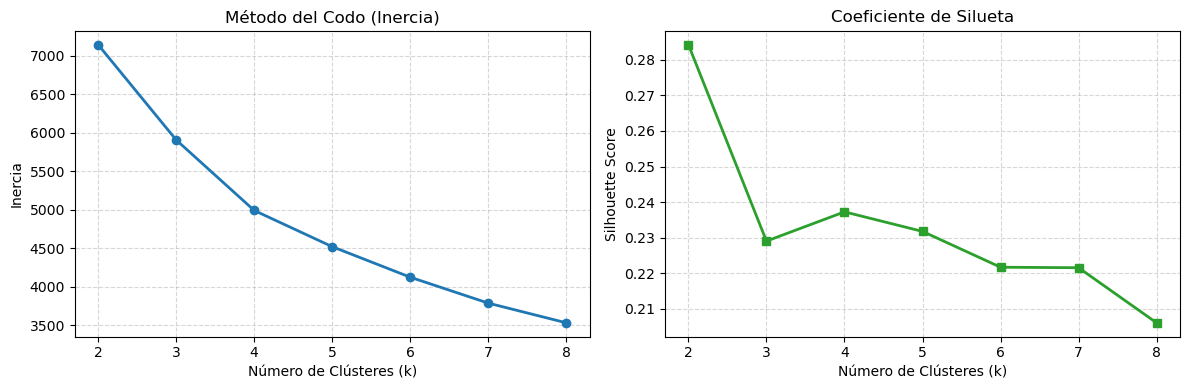

In [24]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Usamos únicamente los 4 componentes retenidos por Kaiser
X_pca_4 = X_pca[:, :4]

inertias = []
silhouettes = []
rango_k = range(2, 9)

for k in rango_k:
  km = KMeans(n_clusters=k, random_state=42, n_init=20)
  labels = km.fit_predict(X_pca_4)
  inertias.append(km.inertia_)
  silhouettes.append(silhouette_score(X_pca_4, labels))

# Tabla comparativa
metricas_k = pd.DataFrame({
    'k': list(rango_k),
    'Inercia': inertias,
    'Silhouette_Score': silhouettes,
})
print('===== MÉTRICAS PARA ELEGIR K ÓPTIMO =====')
print(metricas_k.round(4).to_string(index=False))

# Gráfica doble: Codo y Silueta
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(rango_k, inertias, marker='o', color='#1f77b4', linewidth=2)
ax[0].set_title('Método del Codo (Inercia)')
ax[0].set_xlabel('Número de Clústeres (k)')
ax[0].set_ylabel('Inercia')
ax[0].grid(True, linestyle='--', alpha=0.5)

ax[1].plot(rango_k, silhouettes, marker='s', color='#2ca02c', linewidth=2)
ax[1].set_title('Coeficiente de Silueta')
ax[1].set_xlabel('Número de Clústeres (k)')
ax[1].set_ylabel('Silhouette Score')
ax[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

C:\Users\mcami\anaconda3\envs\IntroIDIA\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(


===== DISTRIBUCIÓN DE ENTIDADES POR CLÚSTER =====
Cluster
0    331
1    371
2    320
3    295
Name: count, dtype: int64

===== PERFIL PROMEDIO DE KPIs POR CLÚSTER =====
Cluster                           0        1        2        3
hhi_valor                     0.182    0.078    0.146    0.220
hhi_n                         0.038    0.024    0.007    0.051
pct_valor_directa             0.534    0.791    0.477    0.045
pct_valor_regimen_esp         0.106    0.030    0.177    0.680
pct_contratos_ops             0.739    0.893    0.807    0.451
pct_valor_pyme                0.431    0.215    0.233    0.534
pct_valor_ene_feb_anual       0.136    0.409    0.210    0.180
pct_valor_nov_dic_anual       0.310    0.097    0.230    0.165
hhi_ordenador                 0.901    0.846    0.701    0.895
duracion_mediana_dias       118.175  179.478  207.205  113.617
log_valor_total              21.507   21.772   24.858   21.462
pct_valor_inversion           0.688    0.495    0.657    0.199
tasa_contrat

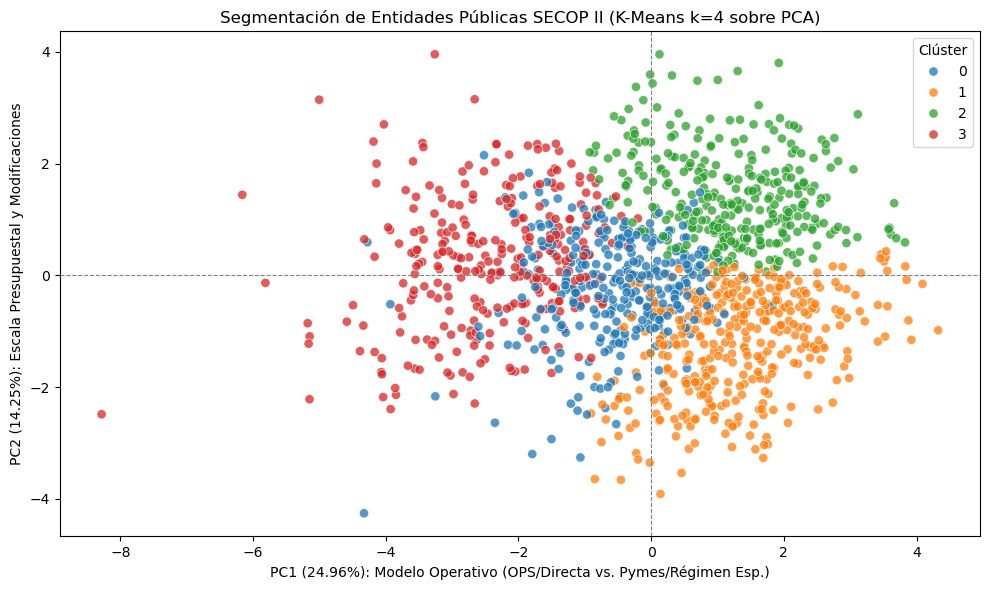

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans

# 1. Entrenamos K-Means definitivo con k=4 sobre los 4 componentes principales
kmeans_final = KMeans(n_clusters=4, random_state=42, n_init=30)
df_modelo['Cluster'] = kmeans_final.fit_predict(X_pca[:, :4])

# Guardamos también las coordenadas PC1 y PC2 para graficar
df_modelo['PC1'] = X_pca[:, 0]
df_modelo['PC2'] = X_pca[:, 1]

# 2. Conteo de entidades por clúster
print('===== DISTRIBUCIÓN DE ENTIDADES POR CLÚSTER =====')
print(df_modelo['Cluster'].value_counts().sort_index())

# 3. Perfil promedio de los 13 KPIs originales por clúster
perfil_clusters = df_modelo.groupby('Cluster')[features_pca].mean()
print('\n===== PERFIL PROMEDIO DE KPIs POR CLÚSTER =====')
print(perfil_clusters.T.round(3))

# 4. Ejemplos reales de entidades en cada clúster (las 4 de mayor presupuesto por grupo)
print('\n===== EJEMPLOS DE ENTIDADES REPRESENTATIVAS POR CLÚSTER =====')
for c in range(4):
  top_ent = (
      df_modelo[df_modelo['Cluster'] == c]
      .sort_values(by='total_valor', ascending=False)
      .index[:4]
      .tolist()
  )
  print(f'Cluster {c}: {top_ent}')

# 5. Mapa 2D de los Clústeres en el plano PCA (PC1 vs PC2)
plt.figure(figsize=(10, 6))
palette = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']

sns.scatterplot(
    data=df_modelo,
    x='PC1',
    y='PC2',
    hue='Cluster',
    palette=palette,
    alpha=0.75,
    s=45,
)

plt.axhline(0, color='gray', linestyle='--', linewidth=0.8)
plt.axvline(0, color='gray', linestyle='--', linewidth=0.8)
plt.title(
    'Segmentación de Entidades Públicas SECOP II (K-Means k=4 sobre PCA)',
    fontsize=12,
)
plt.xlabel('PC1 (24.96%): Modelo Operativo (OPS/Directa vs. Pymes/Régimen Esp.)')
plt.ylabel('PC2 (14.25%): Escala Presupuestal y Modificaciones')
plt.legend(title='Clúster')
plt.tight_layout()
plt.show()